# 06 – Engineering interpretation: forecast-based ventilation
Turns headcount forecasts into outdoor-air requirements and asks the engineering question behind the project: **would ventilating to the day-ahead forecast save outdoor air (and conditioning energy) compared with a fixed schedule, without under-ventilating occupied rooms?**

**Requirement:** AS 1668.2 (Table A1) requires at least **10 L/s of outdoor air per person** for offices, including meeting rooms. Its floor-area minimum (0.35 L/s/m²) is not applied because each space's floor area is unknown (room mapping unverified) – see Limitations.

**Strategies compared on the test period (1 Jul 2025 – Apr 2026):**

| Strategy | Outdoor air supplied |
|---|---|
| Fixed schedule | Design occupancy × 10 L/s, weekdays 07:00–19:00 (typical building management system) |
| Forecast – weekly profile | Weekly-profile forecast × 10 L/s |
| Forecast – MLP | Chosen model (notebook 04) forecast × 10 L/s |
| Ideal | Actual headcount × 10 L/s (not achievable; lower bound) |

The 15-minute mean headcount is used as the requirement: outdoor air dilutes CO₂ and odours gradually (a room's air-change time constant is typically longer than 15 minutes), so a brief peak within an interval does not need instant extra air.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from occforecast.load import load_cached
from occforecast.resample import resample_all
from occforecast.baselines import weekly_profile
from occforecast.model import make_features, make_model, fit_predict
from occforecast.ventilation import (RATE_OFFICE, outdoor_air_flow, fixed_schedule,
                                     compare_strategies, conditioning_energy_kwh)

DATA = "../data/raw/5occupancySensor_MayToDec2024_9MRows.csv"
SPLIT = pd.Timestamp("2025-07-01", tz="Australia/Melbourne")

events = load_cached(DATA, cache="../data/processed/occupancy.clean.pkl")   # fast after first run
series = resample_all(events, freq="15min", max_hold="48h").sort_index()
labels = {s: f"Space {chr(65 + i)}" for i, s in enumerate(sorted(events["space"].unique()))}
ys = {labels[sp]: g for sp, g in series.groupby("space")}

## 1. Forecasts and design occupancy
For each space with test data: train the MLP (chosen in notebook 04) and the weekly profile on data before the split. The fixed schedule's **design occupancy** is the 99th percentile of the 15-minute *peak* headcount in the training period – a robust stand-in for the number of people a designer would ventilate for (the true design capacity is unknown).

In [2]:
data = {}
for name, g in ys.items():
    y = g["headcount_mean"]
    test = y[y.index >= SPLIT].dropna()
    if test.empty:
        print(f"{name}: skipped (no test data)")
        continue
    X = make_features(y)
    design = float(g.loc[g.index < SPLIT, "headcount_max"].quantile(0.99))
    data[name] = {
        "actual": test,
        "design": design,
        "Weekly profile": weekly_profile(y[y.index < SPLIT], test.index),
        "MLP": fit_predict(y, SPLIT, make_model("mlp"), features=X).reindex(test.index),
    }
    print(f"{name}: design occupancy {design:.0f} people, {len(test):,} test intervals")

Space A: design occupancy 9 people, 28,413 test intervals
Space B: design occupancy 13 people, 28,409 test intervals
Space C: skipped (no test data)
Space D: design occupancy 8 people, 28,413 test intervals
Space E: design occupancy 16 people, 28,256 test intervals


## 2. Outdoor air and under-ventilation by strategy
For each strategy: total outdoor air supplied over the test period, the ratio to what was actually required, the percentage of **occupied** intervals that were under-ventilated, and the **shortfall in person-hours** (how many person-hours did not receive the full 10 L/s).

In [3]:
def strategies(d, margin=0.0):
    """Supplied flow (L/s) for each strategy; forecast strategies scaled by (1 + margin)."""
    idx = d["actual"].index
    return {
        "Fixed schedule": fixed_schedule(idx, d["design"]),
        "Forecast – weekly profile": outdoor_air_flow(d["Weekly profile"].fillna(0) * (1 + margin)),
        "Forecast – MLP": outdoor_air_flow(d["MLP"].fillna(0) * (1 + margin)),
        "Ideal (actual headcount)": outdoor_air_flow(d["actual"]),
    }

per_space = []
for name, d in data.items():
    res = compare_strategies(outdoor_air_flow(d["actual"]), strategies(d))
    res["space"] = name
    per_space.append(res.reset_index())
per_space = pd.concat(per_space)

order = ["Fixed schedule", "Forecast – weekly profile", "Forecast – MLP", "Ideal (actual headcount)"]
total = per_space.groupby("strategy").agg(air_m3=("air_m3", "sum"),
                                          shortfall_person_h=("shortfall_person_h", "sum"),
                                          under_vent_intervals_pct=("under_vent_intervals_pct", "mean")).loc[order]
total["air vs fixed (%)"] = 100 * total["air_m3"] / total.loc["Fixed schedule", "air_m3"]
display(total.round(1))
display(per_space.pivot_table(index="space", columns="strategy", values="air_vs_required")[order].round(2)
        .rename_axis(None, axis=1).style.set_caption("Air supplied ÷ air required, per space"))

,air_m3,shortfall_person_h,under_vent_intervals_pct,air vs fixed (%)
strategy,,,,
Fixed schedule,4205952.0,4025.6,41.5,100.0
Forecast – weekly profile,717784.8,6078.4,46.0,17.1
Forecast – MLP,618100.9,6472.9,51.8,14.7
Ideal (actual headcount),594859.2,0.0,0.0,14.1


,Fixed schedule,Forecast – weekly profile,Forecast – MLP,Ideal (actual headcount)
space,,,,
Space A,8.050000,1.400000,1.110000,1.000000
Space B,9.070000,1.450000,1.080000,1.000000
Space D,4.910000,1.000000,1.030000,1.000000
Space E,6.870000,1.110000,0.980000,1.000000


**Findings:** the fixed schedule is both **wasteful and unsafe**. It supplies 4.2 million m³ of outdoor air, 5–9× what the occupants actually required, yet 41.5% of occupied intervals are still under-ventilated (4,026 person-hours), because spaces are used outside 07:00–19:00 on weekdays and some peaks exceed the design occupancy. Ventilating to the MLP forecast uses only **14.7% of the fixed schedule's air (−85%)**, within 4% of the ideal (14.1%). However, it under-ventilates more (6,473 person-hours), because the forecast tracks the *average* and under-predicts peaks.

A better forecast is not automatically a safer one. The MLP is more accurate than the weekly profile, supplying 1.0–1.1× the required air per space versus 1.0–1.45×, but it has a slightly *larger* shortfall (6,473 vs 6,078 person-hours), because the weekly profile's over-prediction acts as an accidental safety margin. The models are trained to minimise symmetric squared error, which penalises over- and under-prediction equally, whereas for ventilation under-prediction matters more. Training on an asymmetric loss (e.g. forecasting an upper quantile) is the natural improvement.

## 3. One week of ventilation

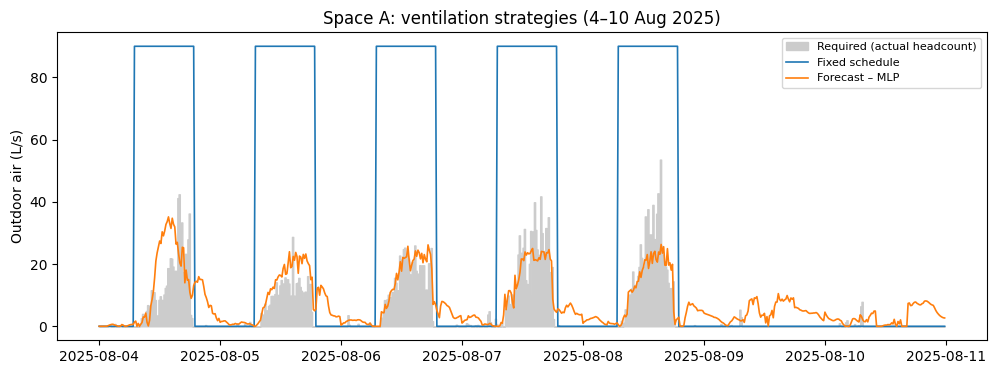

In [4]:
name = "Space A"
d = data[name]
s = strategies(d)
wk = slice("2025-08-04", "2025-08-10")
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(s["Ideal (actual headcount)"][wk].index, s["Ideal (actual headcount)"][wk], color="0.8",
                label="Required (actual headcount)", step="post")
ax.plot(s["Fixed schedule"][wk], lw=1.2, label="Fixed schedule")
ax.plot(s["Forecast – MLP"][wk], lw=1.2, label="Forecast – MLP")
ax.set_ylabel("Outdoor air (L/s)"); ax.set_title(f"{name}: ventilation strategies (4–10 Aug 2025)")
ax.legend(fontsize=8); plt.show()

**Findings:** the fixed schedule supplies 90 L/s (9 people) for the whole 07:00–19:00 window every weekday, while the space mostly needs 0–40 L/s, so most of that air is wasted. The MLP-based supply follows the daily shape closely but sits below the short peaks (≈ 20–25 L/s forecast against 40–50 L/s actual), which is where its shortfall comes from. At the weekend it supplies a little air (≈ 5–10 L/s) when the space is almost empty, a small over-supply.

## 4. Safety margin: trading air for comfort
Forecasts under-predict short peaks, so a practical controller would add a safety margin. Scaling the MLP forecast by (1 + margin) shows the trade-off between outdoor air used and under-ventilation.

,air_m3,shortfall_person_h,under_vent_intervals_pct,air vs fixed (%)
margin,,,,
0.00,618100.9,6472.9,51.8,14.7
0.25,772626.1,5224.9,42.4,18.4
0.50,927151.3,4311.4,35.2,22.0
1.00,1236201.7,3155.2,25.7,29.4
1.50,1545252.1,2490.8,20.1,36.7
2.00,1854302.6,2066.9,16.7,44.1
3.00,2472403.4,1553.3,12.7,58.8


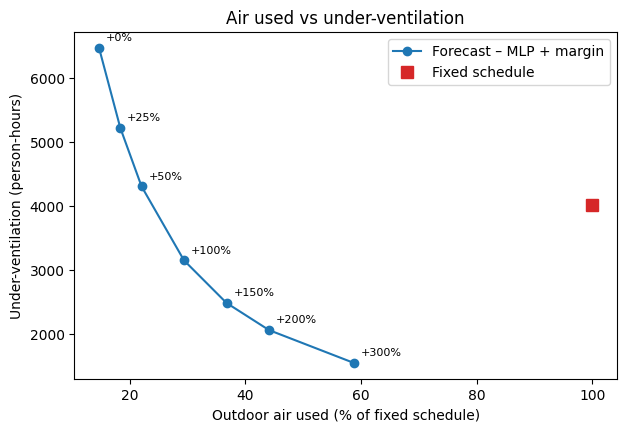

In [5]:
rows = []
for margin in [0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0]:
    parts = [compare_strategies(outdoor_air_flow(d["actual"]), strategies(d, margin))
             .loc[["Forecast – MLP"]] for d in data.values()]
    r = pd.concat(parts)
    rows.append({"margin": margin, "air_m3": r["air_m3"].sum(),
                 "shortfall_person_h": r["shortfall_person_h"].sum(),
                 "under_vent_intervals_pct": r["under_vent_intervals_pct"].mean()})
trade = pd.DataFrame(rows).set_index("margin")
fixed_air, fixed_short = total.loc["Fixed schedule", ["air_m3", "shortfall_person_h"]]
trade["air vs fixed (%)"] = 100 * trade["air_m3"] / fixed_air
display(trade.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(trade["air vs fixed (%)"], trade["shortfall_person_h"], marker="o", label="Forecast – MLP + margin")
for m, r in trade.iterrows():
    ax.annotate(f"+{m:.0%}", (r["air vs fixed (%)"], r["shortfall_person_h"]), textcoords="offset points",
                xytext=(5, 5), fontsize=8)
ax.plot(100, fixed_short, "s", ms=9, color="C3", label="Fixed schedule")
ax.set_xlabel("Outdoor air used (% of fixed schedule)")
ax.set_ylabel("Under-ventilation (person-hours)")
ax.set_title("Air used vs under-ventilation"); ax.legend(); plt.show()

**Findings:** adding a safety margin trades air for comfort smoothly. With **+50%**, the shortfall (4,311 person-hours) is close to the fixed schedule's (4,026) while using only **22% of its air**. With **+100%**, forecast-based ventilation beats the fixed schedule on **both** measures: 22% less under-ventilation (3,155 vs 4,026 person-hours) and **71% less outdoor air** (29.4% of the fixed schedule). No margin removes under-ventilation entirely (still 1,553 person-hours at +300%), because some occupancy happens when the forecast is near zero and scaling zero gives zero. An additive minimum or live occupancy feedback would be needed for those cases.

## 5. Indicative conditioning energy
Outdoor air must be heated or cooled to indoor temperature. Using `E = ρ·V·c_p·ΔT` with an **assumed** average indoor–outdoor difference of 8 K (illustrative for Melbourne; ignores humidity, heat recovery and plant efficiency), the air volumes above translate to the following sensible-energy loads over the test period.

In [6]:
DELTA_T = 8.0   # K, assumed average indoor-outdoor temperature difference (illustrative)
energy = pd.DataFrame({
    "Air (m³)": total["air_m3"],
    "Energy (kWh, indicative)": [conditioning_energy_kwh(v, DELTA_T) for v in total["air_m3"]],
})
energy["vs fixed (%)"] = 100 * energy["Energy (kWh, indicative)"] / energy.loc["Fixed schedule", "Energy (kWh, indicative)"]
display(energy.round(0))

,Air (m³),"Energy (kWh, indicative)",vs fixed (%)
strategy,,,
Fixed schedule,4205952.0,11272.0,100.0
Forecast – weekly profile,717785.0,1924.0,17.0
Forecast – MLP,618101.0,1657.0,15.0
Ideal (actual headcount),594859.0,1594.0,14.0


**Findings:** with the assumed ΔT of 8 K, conditioning the fixed schedule's outdoor air needs ≈ 11,300 kWh over the test period (four spaces, ≈ 10 months), against ≈ 1,660 kWh for MLP-based ventilation (−85%) and ≈ 3,300 kWh with the +100% safety margin (−71%), the setting that also beats the fixed schedule on under-ventilation. The percentage savings equal the air savings because energy is proportional to volume. The absolute kWh values depend directly on the assumed ΔT and are indicative only.

## 6. Limitations
- **Floor-area minimum not applied:** AS 1668.2's 0.35 L/s/m² minimum could not be included because floor areas are unknown; in practice it would set a non-zero minimum supply even in empty rooms, reducing the savings.
- **Design occupancy is estimated** from observed peaks, not from the rooms' design capacity.
- **15-minute mean headcount** is used as the requirement; very short peaks are averaged out.
- **Sensor accuracy:** the headcount itself is not independently validated (no ground truth).
- **Energy is indicative only:** fixed ΔT, sensible heat only, no heat recovery or plant efficiency.
- **Symmetric training loss:** the forecasting models minimise squared error, which treats over- and under-prediction equally; ventilation safety would benefit from an asymmetric loss (e.g. quantile regression).
- **Control is idealised:** real systems have minimum damper positions, fan limits and response delays, and would likely combine the forecast with live CO₂ or occupancy feedback.